# MsPacMan Q-table · Poengbonus i B

Dette er et oppfølgingsforsøk til B fra Q-tabellnotebooken. Agenten får en liten bonus for hver økning i spillscore og +1 når den når 2 000 poeng. Standardvekten er 0,25, som gir totalt 0,25 ekstra bonus før diskontering ved nøyaktig 2 000 spillpoeng.

Kjør første målepunkt ved 16 384 interaksjoner. Se på underveiskurven. Bytt deretter verdien i den valgfrie fortsettelsescellen til 32 768 eller 65 536 hvis du vil gi de samme agentene mer trening. Fortsettelse bruker den aktive notebook-kjernen, som holder på Q-tabellene, miljøtilstandene og de tilfeldige generatorene. Resultatmappene lagrer evaluerbare modeller for hvert fullført målepunkt.

Bonusforsøket bruker de samme tre treningsfrøene, tilstandsnøklene, handlingene og epsilon-planen som den opprinnelige B-kjøringen. Standardbudsjettet og målet beholdes ved den første sammenligningen. Baseline leses fra den rapporterte Q-tabellkjøringen. Ekstra trening måles mot det nye målepunktet ved 16 384.

Velg om du vil fortsette ut fra underveiskurven. Sluttevaluering bruker den eksisterende testfrølisten for direkte sammenligning. Målepunktene bruker samme liste og bør leses som parvise målinger på de samme episodene. Bruk suksessrate og rå spillpoeng for å sammenligne belønningsoppsettene.

Kjør notebooken med Python 3.12 fra oppgavemappen. Hvert evaluert målepunkt kan åpnes i dashboardet med Oppdater liste.

In [1]:
%pip install "gymnasium[atari]==1.2.3" "ale-py==0.11.2" "opencv-python-headless>=4.10,<5" "pandas>=2.2,<3" "matplotlib>=3.9,<4" "joblib>=1.4,<2"

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from dataclasses import asdict, dataclass
from datetime import datetime, timezone
from functools import partial
from importlib.metadata import version
from pathlib import Path
from time import perf_counter
import gzip
import json
import os
import platform

import ale_py
import gymnasium as gym
from gymnasium.wrappers import FrameStackObservation, RecordEpisodeStatistics, ResizeObservation, TimeLimit
from IPython.display import display
from joblib import Parallel, delayed, parallel_config
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

gym.register_envs(ale_py)


ENV_ID = "ALE/MsPacman-v5"
SUCCESS_POINTS = 2_000
MAX_EPISODE_STEPS = 1_024
FRAME_SKIP = 4
OBS_SHAPE = (4, 42, 42)
TRAINING_SEEDS = (42, 43, 44)
MONITOR_SEEDS = tuple(range(100_000, 100_008))
TEST_SEEDS = tuple(range(200_000, 200_200))
CHECKPOINT_EVERY = 4_096
MILESTONES = (16_384, 32_768, 65_536)
TRAIN_ENVS = 8
EVAL_ENVS = 24
EVAL_WORKERS = min(4, os.cpu_count() or 1)
BASELINE_DIR = Path("part2_results/20261121T215129452556Z")
SCORE_BONUS = 0.25
GAMMA = 0.99
Q_TABLE = dict(alpha=0.15, epsilon_start=1.0, epsilon_end=0.10,
               exploration_steps=12_288, position_bin=12, ghost_radius=24)
ALGORITHM = "Q-table"
SETTING = "B"
POLICY = "greedy Q-table (current direction on ties when available)"


@dataclass(frozen=True)
class Setting:
    sticky: float
    step_penalty: float = 0.0
    maze: int = 0
    score_bonus: float = 0.0


SETTINGS = {SETTING: Setting(sticky=0.25, score_bonus=SCORE_BONUS)}
assert np.isfinite(SCORE_BONUS) and SCORE_BONUS > 0
assert CHECKPOINT_EVERY % TRAIN_ENVS == 0
assert all(total % CHECKPOINT_EVERY == 0 for total in MILESTONES)

In [3]:
class MazeStart(gym.Wrapper):
    """Select the ROM's starting maze before the initial frame is stacked."""

    def __init__(self, env, maze):
        super().__init__(env)
        self.maze = maze
        self.ale = self.unwrapped.ale
        self.noop = self.unwrapped.get_action_meanings().index("NOOP")

    def reset(self, *, seed=None, options=None):
        self.env.reset(seed=seed, options=options)
        if self.maze != 0:
            self.ale.setRAM(0, self.maze)
        observation, points, terminated, truncated, info = self.env.step(self.noop)
        if points != 0 or terminated or truncated or self.ale.getRAM()[0] != self.maze:
            raise RuntimeError("Unexpected MsPacman state during maze reset.")
        return observation, info


class ScoreGoal(gym.Wrapper):
    def __init__(self, env, setting):
        super().__init__(env)
        self.setting = setting
        self.ale = self.unwrapped.ale

    def reset(self, **kwargs):
        self.score = 0.0
        return self.env.reset(**kwargs)

    def step(self, action):
        obs, points, game_over, timeout, info = self.env.step(action)
        self.score += float(points)
        success = self.score >= SUCCESS_POINTS
        maze_exit = int(self.ale.getRAM()[0]) != self.setting.maze
        terminated = bool(success or game_over or maze_exit)
        truncated = bool(timeout and not terminated)
        outcome = ("success" if success else "game_over" if game_over else
                   "maze_exit" if maze_exit else "timeout" if truncated else "in_progress")
        reward = (float(success) + self.setting.score_bonus * float(points) / SUCCESS_POINTS
                  - self.setting.step_penalty)
        info.update(raw_points=float(points), raw_score=self.score, outcome=outcome)
        return obs, reward, terminated, truncated, info


def tabular_state(ram):
    """Encode coarse player position, heading and the nearest nearby ghost."""
    x, y = int(ram[10]), int(ram[16])
    heading = int(ram[56]) & 3
    sector = 9
    if ram[47] > 0:
        ghosts = range(1 + min(int(ram[19]), 3))
        offsets = [(int(ram[6 + i]) - x, int(ram[12 + i]) - y) for i in ghosts]
        dx, dy = min(offsets, key=lambda offset: abs(offset[0]) + abs(offset[1]))
        if abs(dx) + abs(dy) <= Q_TABLE["ghost_radius"]:
            sx = int(dx > 0) - int(dx < 0)
            sy = int(dy > 0) - int(dy < 0)
            sector = (sx + 1) * 3 + sy + 1
    position_bin = Q_TABLE["position_bin"]
    return x // position_bin, y // position_bin, heading, sector


class TabularObservation(gym.ObservationWrapper):
    def __init__(self, env):
        super().__init__(env)
        positions = 255 // Q_TABLE["position_bin"] + 1
        self.observation_space = gym.spaces.MultiDiscrete([positions, positions, 4, 10])

    def observation(self, observation):
        return np.asarray(tabular_state(self.unwrapped.ale.getRAM()), dtype=np.int64)


def build_environment(setting_name, algorithm=None):
    setting = SETTINGS[setting_name]
    env = gym.make(ENV_ID, obs_type="grayscale", frameskip=FRAME_SKIP,
                   repeat_action_probability=setting.sticky, full_action_space=False)
    env = MazeStart(env, setting.maze)
    env = ResizeObservation(env, OBS_SHAPE[1:])
    env = FrameStackObservation(env, stack_size=OBS_SHAPE[0])
    env = TimeLimit(env, max_episode_steps=MAX_EPISODE_STEPS)
    env = RecordEpisodeStatistics(ScoreGoal(env, setting))
    return TabularObservation(env) if algorithm == "Q-table" else env


with build_environment(SETTING, ALGORITHM) as probe:
    initial, _ = probe.reset(seed=900_001)
    assert probe.observation_space.contains(initial)
    ACTION_NAMES = probe.unwrapped.get_action_meanings()
    assert [ACTION_NAMES[i] for i in (1, 2, 4, 3)] == ["UP", "RIGHT", "DOWN", "LEFT"]

In [4]:
class TrainingBatch:
    def __init__(self, setting, seed, algorithm):
        self.env = gym.vector.SyncVectorEnv(
            [partial(build_environment, setting, algorithm) for _ in range(TRAIN_ENVS)],
            autoreset_mode=gym.vector.AutoresetMode.DISABLED,
        )
        env_seeds = [seed * 1_000 + i for i in range(TRAIN_ENVS)]
        self.obs, _ = self.env.reset(seed=env_seeds)
        self.actions = self.env.single_action_space.n
        self.interactions = 0
        self.episodes = []

    def step(self, actions):
        next_obs, rewards, terminated, truncated, info = self.env.step(actions)
        self.interactions += TRAIN_ENVS
        done = terminated | truncated
        for i in np.flatnonzero(done):
            self.episodes.append(dict(interactions=self.interactions, env_index=int(i),
                                      episode_return=float(info["episode"]["r"][i]),
                                      length=int(info["episode"]["l"][i]),
                                      raw_score=float(info["raw_score"][i]),
                                      outcome=str(info["outcome"][i])))
        if done.any():
            self.obs, _ = self.env.reset(options={"reset_mask": done})
        else:
            self.obs = next_obs
        return next_obs, rewards, terminated, done


class TabularQModel:
    def __init__(self, action_count):
        self.zero = np.zeros(action_count, dtype=np.float64)
        self.q = {}

    def values(self, state):
        return self.q.get(tuple(state), self.zero)

    def greedy(self, state):
        values = self.values(state)
        best = int(values.argmax())
        forward = (1, 2, 4, 3)[state[2]]  # UP, RIGHT, DOWN, LEFT in the ALE minimal action space.
        return forward if values[forward] == values[best] else best

    def save(self, path):
        keys = np.asarray(list(self.q), dtype=np.int16).reshape(-1, 4)
        values = np.asarray(list(self.q.values()), dtype=np.float64).reshape(-1, len(self.zero))
        np.savez_compressed(path, keys=keys, values=values)


class TabularQTrainer:
    def __init__(self, action_count, seed):
        self.model = TabularQModel(action_count)
        self.rng = np.random.default_rng(seed)
        self.updates = 0

    def train_until(self, batch, stop):
        cfg = Q_TABLE
        while batch.interactions < stop:
            observations = batch.obs
            epsilon = np.interp(batch.interactions, [0, cfg["exploration_steps"]],
                                [cfg["epsilon_start"], cfg["epsilon_end"]])
            actions = np.array([self.rng.integers(batch.actions) if self.rng.random() < epsilon
                                else self.model.greedy(state) for state in observations])
            next_obs, rewards, terminated, _ = batch.step(actions)
            for state, action, reward, next_state, terminal in zip(observations, actions, rewards, next_obs, terminated):
                key = tuple(state)
                if key not in self.model.q:
                    self.model.q[key] = self.model.zero.copy()
                values = self.model.q[key]
                future = 0.0 if terminal else self.model.values(next_state).max()
                values[action] += cfg["alpha"] * (reward + GAMMA * future - values[action])
                self.updates += 1

In [5]:
def evaluate(model, setting, seeds, record_actions=False):
    results, traces = [], []
    start = perf_counter()
    envs = [build_environment(setting, ALGORITHM) for _ in range(min(EVAL_ENVS, len(seeds)))]
    try:
        for offset in range(0, len(seeds), len(envs)):
            batch_seeds = seeds[offset:offset + len(envs)]
            ob = {i: envs[i].reset(seed=seed)[0] for i, seed in enumerate(batch_seeds)}
            action_logs = [[] for _ in batch_seeds]
            seen = np.zeros(len(batch_seeds), dtype=int)
            for step in range(MAX_EPISODE_STEPS):
                if not ob:
                    break
                slots = list(ob)
                actions = [model.greedy(ob[i]) for i in slots]
                for i in slots:
                    seen[i] += tuple(ob[i]) in model.q
                for i, action in zip(slots, actions):
                    ob[i], _, terminated, truncated, info = envs[i].step(int(action))
                    if record_actions:
                        action_logs[i].append(int(action))
                    if terminated or truncated:
                        seed = batch_seeds[i]
                        results.append(dict(eval_seed=seed, length=int(info["episode"]["l"]),
                                            episode_return=float(info["episode"]["r"]),
                                            raw_score=float(info["raw_score"]), outcome=info["outcome"]))
                        results[-1]["known_state_steps"] = int(seen[i])
                        if record_actions:
                            traces.append(dict(eval_seed=seed, actions=action_logs[i]))
                        del ob[i]
            assert not ob, "Gymnasium TimeLimit should end every episode in the batch."
    finally:
        for env in envs:
            env.close()
    return sorted(results, key=lambda row: row["eval_seed"]), traces, perf_counter() - start


def load_model(path):
    model = TabularQModel(len(ACTION_NAMES))
    with np.load(path, allow_pickle=False) as checkpoint:
        model.q = {tuple(key): values.copy() for key, values in
                   zip(checkpoint["keys"], checkpoint["values"], strict=True)}
    return model

def summarize(episodes):
    success = [row["length"] for row in episodes if row["outcome"] == "success"]
    failure = [row["length"] for row in episodes if row["outcome"] != "success"]
    coverage = {}
    if "known_state_steps" in episodes[0]:
        coverage["known_state_rate"] = sum(row["known_state_steps"] for row in episodes) / sum(
            row["length"] for row in episodes)
    return dict(**coverage, episodes=len(episodes), successes=len(success), failures=len(failure),
                success_rate=len(success) / len(episodes), failure_rate=len(failure) / len(episodes),
                mean_return=float(np.mean([row["episode_return"] for row in episodes])),
                mean_raw_score=float(np.mean([row["raw_score"] for row in episodes])),
                success_length=float(np.mean(success)) if success else np.nan,
                failure_length=float(np.mean(failure)) if failure else np.nan,
                eval_interactions=sum(row["length"] for row in episodes))



def run_test(run, setting, output):
    gym.register_envs(ale_py)
    eval_id = f"{run['run_id']}__eval-{setting}"
    model = load_model(output / run["checkpoint"])
    rows, traces, elapsed = evaluate(model, setting, TEST_SEEDS, record_actions=True)
    folder = output / run["run_id"]
    pd.DataFrame(rows).assign(eval_id=eval_id).to_csv(folder / f"evaluation_{setting}.csv", index=False)
    with gzip.open(folder / f"actions_{setting}.jsonl.gz", "wt", encoding="utf-8") as stream:
        for trace in sorted(traces, key=lambda row: row["eval_seed"]):
            stream.write(json.dumps(trace, separators=(",", ":")) + "\n")
    print(f"{eval_id}: {len(rows)} held-out episodes in {elapsed:.1f} s", flush=True)
    return dict(eval_id=eval_id, setting=setting, policy=POLICY, eval_seconds=elapsed,
                **run, **summarize(rows))

In [6]:
def cpu_name():
    if platform.system() == "Windows":
        import winreg
        with winreg.OpenKey(winreg.HKEY_LOCAL_MACHINE, r"HARDWARE\DESCRIPTION\System\CentralProcessor\0") as key:
            return winreg.QueryValueEx(key, "ProcessorNameString")[0].strip()
    if Path("/proc/cpuinfo").exists():
        for line in Path("/proc/cpuinfo").read_text().splitlines():
            if line.startswith("model name"):
                return line.split(":", 1)[1].strip()
    return platform.processor() or platform.machine()


def experiment_settings(budget):
    return dict(env_id=ENV_ID, success_points=SUCCESS_POINTS, max_episode_steps=MAX_EPISODE_STEPS,
                observation_shape=OBS_SHAPE, action_names=ACTION_NAMES, frame_skip=FRAME_SKIP,
                settings={SETTING: asdict(SETTINGS[SETTING])}, training_seeds=TRAINING_SEEDS,
                monitor_seeds=MONITOR_SEEDS, test_seeds=TEST_SEEDS, interaction_budget=budget,
                checkpoint_every=CHECKPOINT_EVERY, gamma=GAMMA, algorithms={ALGORITHM: Q_TABLE},
                eval_modes={ALGORITHM: POLICY},
                hardware=dict(device="cpu", cpu=cpu_name(), logical_cpus=os.cpu_count(),
                              training_envs=TRAIN_ENVS, evaluation_batch_size=EVAL_ENVS,
                              evaluation_workers=EVAL_WORKERS),
                software={name: version(name) for name in ("gymnasium", "ale-py", "numpy",
                          "opencv-python-headless", "pandas", "matplotlib", "joblib")},
                python=platform.python_version(), operating_system=platform.platform())


class AgentProgress:
    def __init__(self, seed):
        self.seed = seed
        self.run_id = f"{SETTING}-{ALGORITHM}-s{seed}"
        self.batch = TrainingBatch(SETTING, seed, ALGORITHM)
        self.trainer = TabularQTrainer(self.batch.actions, seed)
        self.training_seconds = 0.0
        self.curve = []
        self.monitor_episodes = []

    def advance_to(self, budget):
        monitored = {row["interactions"] for row in self.curve}
        for target in range(0, budget + 1, CHECKPOINT_EVERY):
            if target in monitored:
                continue
            if self.batch.interactions < target:
                start = perf_counter()
                try:
                    self.trainer.train_until(self.batch, target)
                finally:
                    self.training_seconds += perf_counter() - start
            assert self.batch.interactions == target
            episodes, _, elapsed = evaluate(self.trainer.model, SETTING, MONITOR_SEEDS)
            self.monitor_episodes.extend(dict(row, run_id=self.run_id, interactions=target) for row in episodes)
            record = dict(run_id=self.run_id, setting=SETTING, algorithm=ALGORITHM, train_seed=self.seed,
                          interactions=target, training_seconds=self.training_seconds,
                          monitor_seconds=elapsed, **summarize(episodes))
            self.curve.append(record)
            print(f"{self.run_id}: {target:,} interactions, monitor score {record['mean_raw_score']:.1f}", flush=True)

    def save(self, output):
        folder = output / self.run_id
        folder.mkdir()
        checkpoint = folder / "q_table.npz"
        self.trainer.model.save(checkpoint)
        pd.DataFrame(self.monitor_episodes).to_csv(folder / "monitor_episodes.csv", index=False)
        pd.DataFrame(self.batch.episodes).assign(run_id=self.run_id).to_csv(folder / "training_episodes.csv", index=False)
        config = dict(run_id=self.run_id, train_setting=SETTING, algorithm=ALGORITHM, train_seed=self.seed,
                      training_interactions=self.batch.interactions, training_seconds=self.training_seconds,
                      optimizer_updates=self.trainer.updates, completed_training_episodes=len(self.batch.episodes),
                      params=Q_TABLE, env_seeds=[self.seed * 1_000 + i for i in range(TRAIN_ENVS)],
                      q_table_states=len(self.trainer.model.q), checkpoint=checkpoint.relative_to(output).as_posix())
        (folder / "run.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
        return config


LEARNERS = {}
STAGES = {}


def train_to(budget):
    if budget not in MILESTONES:
        raise ValueError(f"Choose one of these budgets: {MILESTONES}.")
    if budget in STAGES:
        return STAGES[budget]
    if any(agent.batch.interactions > budget for agent in LEARNERS.values()):
        raise ValueError("The live agents are past this budget. Use an earlier saved stage.")
    for seed in TRAINING_SEEDS:
        if seed not in LEARNERS:
            LEARNERS[seed] = AgentProgress(seed)
        LEARNERS[seed].advance_to(budget)

    label = f"Q-table bonus · {budget:,}".replace(",", " ")
    output = Path("part2_results") / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
    output.mkdir(parents=True)
    manifest = dict(experiment_settings(budget), label=label, baseline_directory=str(BASELINE_DIR))
    (output / "experiment.json").write_text(json.dumps(manifest, indent=2, ensure_ascii=False), encoding="utf-8")
    runs = [agent.save(output) for agent in LEARNERS.values()]
    learning = pd.DataFrame(row for agent in LEARNERS.values() for row in agent.curve)
    learning.to_csv(output / "learning_curves.csv", index=False)
    stage = dict(output=output, budget=budget, runs=runs, learning=learning)
    STAGES[budget] = stage
    print(output)
    return stage

In [7]:
def evaluate_stage(stage):
    output = stage["output"]
    completed = output / "per_agent.csv"
    if completed.is_file():
        return pd.read_csv(completed)
    with parallel_config(backend="loky", inner_max_num_threads=1):
        test_rows = Parallel(n_jobs=EVAL_WORKERS, verbose=5, max_nbytes=None)(
            delayed(run_test)(run, SETTING, output) for run in stage["runs"]
        )
    per_agent = pd.DataFrame(test_rows).sort_values("train_seed")
    assert len(per_agent) == len(TRAINING_SEEDS)
    assert (per_agent["training_interactions"] == stage["budget"]).all()
    assert (per_agent["episodes"] == len(TEST_SEEDS)).all()
    METRICS = ["success_rate", "failure_rate", "mean_return", "mean_raw_score",
               "success_length", "failure_length", "training_interactions", "training_seconds",
               "eval_interactions", "eval_seconds"]
    if "known_state_rate" in per_agent:
        METRICS.append("known_state_rate")
    groups = per_agent.groupby(["setting", "algorithm"])
    means = groups[METRICS].mean()
    variation = groups[METRICS].std(ddof=1)
    outcome_counts = groups[["success_length", "failure_length"]].count().rename(
        columns={"success_length": "agents_with_success", "failure_length": "agents_with_failure"})
    summary = means.join(variation.add_suffix("_sd")).join(outcome_counts)
    summary["n_agents"] = groups.size()
    summary.to_csv(output / "summary.csv")
    
    per_agent = per_agent.drop(columns=["params", "env_seeds"])
    per_agent.to_csv(completed, index=False)
    return per_agent


def baseline():
    if BASELINE_DIR is None:
        return None, None
    required = ("experiment.json", "per_agent.csv", "learning_curves.csv")
    if not all((BASELINE_DIR / filename).is_file() for filename in required):
        print(f"Baseline files missing in {BASELINE_DIR}.")
        return None, None
    original = json.loads((BASELINE_DIR / "experiment.json").read_text(encoding="utf-8"))
    current = json.loads(json.dumps(experiment_settings(MILESTONES[0])))
    fields = ("env_id", "success_points", "max_episode_steps", "frame_skip", "action_names",
              "training_seeds", "test_seeds", "monitor_seeds", "interaction_budget", "gamma")
    mismatches = [key for key in fields if original.get(key) != current[key]]
    setting = dict(original.get("settings", {}).get(SETTING, {}))
    expected = dict(current["settings"][SETTING])
    if setting.pop("score_bonus", 0.0) != 0 or setting != {k: v for k, v in expected.items() if k != "score_bonus"}:
        mismatches.append("B environment")
    if original.get("algorithms", {}).get(ALGORITHM) != Q_TABLE:
        mismatches.append("Q-table configuration")
    if original.get("eval_modes", {}).get(ALGORITHM) != POLICY:
        mismatches.append("evaluation policy")
    if mismatches:
        print("Baseline comparison skipped. Different settings: " + ", ".join(mismatches))
        return None, None
    def b_rows(filename):
        rows = pd.read_csv(BASELINE_DIR / filename)
        return rows[(rows["setting"] == SETTING) & (rows["algorithm"] == ALGORITHM)]
    return b_rows("per_agent.csv"), b_rows("learning_curves.csv")


def report(stage):
    from matplotlib.ticker import PercentFormatter

    output, budget = stage["output"], stage["budget"]
    per_agent = evaluate_stage(stage)
    original, original_curve = baseline()
    common = ["success_rate", "mean_raw_score", "failure_length", "known_state_rate"]
    display(per_agent[["train_seed", "successes", *common, "training_seconds"]].round(4))
    comparisons = []
    if original is not None and budget == MILESTONES[0]:
        comparisons.append(("Score bonus minus original B", original))
    if budget > MILESTONES[0] and MILESTONES[0] in STAGES:
        earlier = STAGES[MILESTONES[0]]["output"] / "per_agent.csv"
        if earlier.is_file():
            comparisons.append(("Continued training minus score bonus at 16,384", pd.read_csv(earlier)))
    if comparisons:
        current = per_agent.set_index("train_seed")[common]
        changes = pd.concat({label: current.subtract(reference.set_index("train_seed")[common])
                             for label, reference in comparisons}, names=["contrast"])
        changes.to_csv(output / "paired_changes.csv")
        print("Mean paired change across training seeds")
        display(changes.groupby("contrast").mean().round(4))

    curves = [("B with score bonus", stage["learning"])]
    if original_curve is not None:
        curves.append(("Original B · " + BASELINE_DIR.name, original_curve))
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True, layout="constrained")
    for ax, (metric, title) in zip(axes, (("mean_raw_score", "Mean raw Atari points"),
                                       ("success_rate", "Success rate"))):
        for label, points in curves:
            groups = points.groupby("interactions")[metric]
            mean, sd = groups.mean(), groups.std(ddof=1).fillna(0)
            ax.plot(mean.index, mean, marker="o", label=label)
            upper = mean + sd
            ax.fill_between(mean.index, (mean - sd).clip(lower=0),
                            upper.clip(upper=1) if metric == "success_rate" else upper, alpha=0.15)
        ax.set(xlabel="Training interactions", ylabel=title)
        ax.grid(alpha=0.2)
    axes[0].legend()
    axes[1].yaxis.set_major_formatter(PercentFormatter(1))
    axes[1].set_ylim(bottom=-0.001, top=min(1.02, max(0.05, axes[1].get_ylim()[1])))
    fig.suptitle(f"B · {budget:,} interactions · {output.name}\nMean ± SD across training seeds · monitoring episodes")
    fig.savefig(output / "learning_curves.png", dpi=160)
    plt.show()
    return per_agent

## Første treningsbudsjett

Tren til 16 384 interaksjoner per agent. Linjene i celleutdataene viser råpoeng på de separate monitoreringsfrøene.

In [8]:
first_stage = train_to(16_384)

B-Q-table-s42: 0 interactions, monitor score 60.0
B-Q-table-s42: 4,096 interactions, monitor score 90.0
B-Q-table-s42: 8,192 interactions, monitor score 123.8
B-Q-table-s42: 12,288 interactions, monitor score 123.8
B-Q-table-s42: 16,384 interactions, monitor score 160.0
B-Q-table-s43: 0 interactions, monitor score 60.0
B-Q-table-s43: 4,096 interactions, monitor score 181.2
B-Q-table-s43: 8,192 interactions, monitor score 140.0
B-Q-table-s43: 12,288 interactions, monitor score 285.0
B-Q-table-s43: 16,384 interactions, monitor score 285.0
B-Q-table-s44: 0 interactions, monitor score 60.0
B-Q-table-s44: 4,096 interactions, monitor score 211.2
B-Q-table-s44: 8,192 interactions, monitor score 107.5
B-Q-table-s44: 12,288 interactions, monitor score 253.8
B-Q-table-s44: 16,384 interactions, monitor score 253.8
part2_results\20261121T225354155485Z


## Evaluer og sammenlign

Denne cellen kjører sluttevaluering og lagrer CSV-er og avspillingsspor. Den viser forskjellen mot den opprinnelige B-kjøringen hvis baselinekonfigurasjonen samsvarer.

[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done   3 out of   3 | elapsed:  1.0min finished


,train_seed,successes,success_rate,mean_raw_score,failure_length,known_state_rate,training_seconds
0,42,0,0.0,160.00,426.02,0.9606,6.4886
1,43,0,0.0,210.85,540.90,0.9976,6.1675
2,44,0,0.0,246.30,514.33,0.9759,6.2877


Mean paired change across training seeds


,success_rate,mean_raw_score,failure_length,known_state_rate
contrast,,,,
Score bonus minus original B,0.0,145.7167,11.75,0.0389


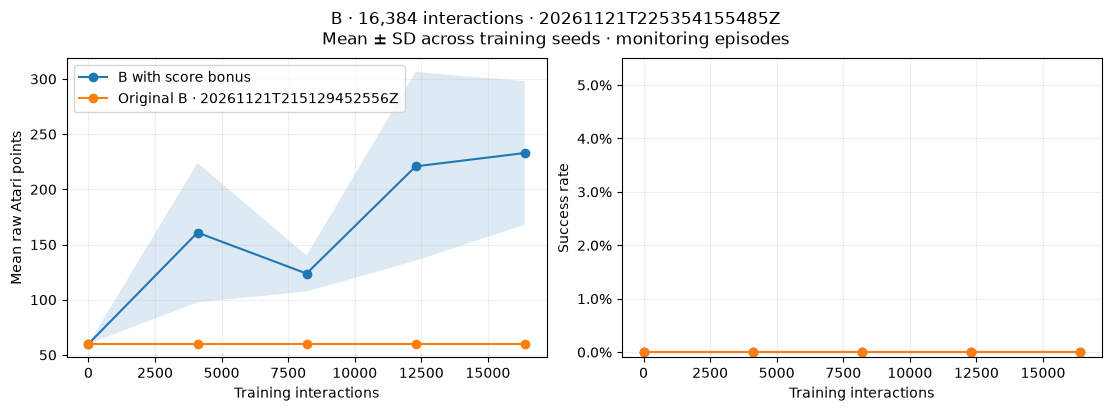

In [9]:
first_results = report(first_stage)

## Valgfri fortsettelse

Se på underveiskurven. Sett EXTEND_TO til 32_768 eller 65_536 og kjør cellen hvis du vil fortsette i samme notebook-kjerne. Hvert budsjett får en egen kjøring i dashboardet.

In [10]:
EXTEND_TO = None  # 32_768 or 65_536
if EXTEND_TO is not None:
    extended_stage = train_to(EXTEND_TO)
    extended_results = report(extended_stage)